# 05 — Birinci məqalənin qara siyahı filtri və ML: müqayisə və MySQL-də yoxlama

1. `sanitizeInput()` / `sanitizeSearch()` Python-a köçürülür (`src/blacklist.py`) və Node.js ilə 50 nümunədə eyniliyi sübut olunur.
2. Filtr detektor kimi: sanitizasiya girişi dəyişdirirsə → "bloklandı". Recall / FPR / F1 və obfuskasiya (ssenari A) recall-u,
   LR baseline və LR + normallaşdırma ilə eyni cədvəldə.
3. Lokal laborator MySQL-də 300 zərərli payload (seed = 42): orijinal, hər obfuskasiya versiyası (ssenari A) və
   sanitizasiyadan keçmiş formalar real olaraq icra olunur.
4. Əsas cədvəl → `results/blacklist_vs_ml.csv`.

**Təhlükəsizlik:** MySQL testi laborator tətbiqin öz bazasında yox, eyni sxem və məlumatlarla ayrıca yaradılmış
`sqli_ml_eval` bazasında, **yalnız SELECT hüququ olan** `sqli_eval` istifadəçisi ilə aparılır (`sql/setup_eval_db.sql`).
`DROP`, `INSERT`, `INTO OUTFILE`, `LOAD_FILE` kimi payload-lar hüquq xətası ilə dayanır. Stacked query-lər
(`; DROP ...`) mümkün deyil: laborator tətbiqdəki kimi `multipleStatements` söndürülüb. `max_execution_time = 2000` ms.

## 0. Mühit

In [1]:
import hashlib
import json
import os
import random
import re
import subprocess
import sys
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from urllib.parse import unquote

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import obfuscation as obf
from blacklist import sanitize_input, sanitize_search

PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"
SERVER_JS = Path(r"C:\Users\Mehman\OneDrive\Desktop\Aztu-projects\meqale son\project-teqdimat"
                 r"\sql-injection - Copy (2)\server.js")

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")

test = pd.read_csv(PROC_DIR / "test_v2.csv", keep_default_na=False, dtype={"Query": str, "Label": int})
malicious = test.loc[test.Label == 1, "Query"].reset_index(drop=True)  # 03-dəki "index" bu sıraya istinad edir
obf_long = pd.read_csv(PROC_DIR / "obfuscated_test_v2.csv", keep_default_na=False)
obf_A = obf_long[obf_long.scenario == "A"].reset_index(drop=True)
TECH_ORDER = list(obf.TECHNIQUES) + ["combination"]

DETECTORS = {
    "Blacklist (Input)": lambda X: np.array([int(sanitize_input(q) != q) for q in X]),
    "Blacklist (Search)": lambda X: np.array([int(sanitize_search(q) != q) for q in X]),
}
for name, file in (("LR baseline", "lr_v2"), ("LR + normallaşdırma", "lr_norm_v2"),
                   ("LR + norm. + augmentation", "lr_norm_aug_v2")):
    model = joblib.load(MODEL_DIR / f"{file}.joblib")
    DETECTORS[name] = model.predict
print(list(DETECTORS))

['Blacklist (Input)', 'Blacklist (Search)', 'LR baseline', 'LR + normallaşdırma', 'LR + norm. + augmentation']


## 1. Filtrin köçürülməsinin yoxlanması: Python ↔ Node.js
Funksiyalar `server.js`-dən **mətn olaraq** çıxarılır (heç bir dəyişiklik edilmədən) və `node -e` ilə işlədilir.
50 nümunə: test dəstindən 35 təsadüfi sorğu (seed = 42) + 15 çətin hal (söz daxilində `OR`/`AND`, iç-içə açar söz,
Unicode böyük-kiçik hərf, JavaScript `trim()` ilə Python `strip()`-in fərqli olduğu boşluq simvolları).

In [2]:
js_src = SERVER_JS.read_text(encoding="utf-8")
js_funcs = re.findall(r"function sanitize(?:Input|Search)\(input\) \{.*?\n\}", js_src, re.S)
assert len(js_funcs) == 2, "server.js-də iki funksiya tapılmadı"
print(js_funcs[0], "\n", js_funcs[1], sep="")

JS_RUNNER = "\n".join(js_funcs) + '''
let d = ''; process.stdin.on('data', c => d += c).on('end', () => {
  const xs = JSON.parse(d);
  console.log(JSON.stringify(xs.map(x => [sanitizeInput(x), sanitizeSearch(x)])));
});'''

EDGE_CASES = ["password", "ORDER BY 1", "android", "UNIUNIONON", "SELSELECTECT 1", "ſelect",
              "\ufeff a \ufeff", "\x1c a \x1c", "\u00a0x\u3000", "\u0085y\u0085", "xp_cmdshell",
              "/*!50000union*/", "1' or '1'='1", "a' UNION SELECT 1 -- ", ""]
samples = test["Query"].sample(35, random_state=SEED).tolist() + EDGE_CASES
proc = subprocess.run(["node", "-e", JS_RUNNER], input=json.dumps(samples), capture_output=True,
                      text=True, encoding="utf-8", check=True)
js_out = json.loads(proc.stdout)
equiv = pd.DataFrame({
    "input": samples,
    "js_input": [a for a, _ in js_out], "py_input": [sanitize_input(s) for s in samples],
    "js_search": [b for _, b in js_out], "py_search": [sanitize_search(s) for s in samples],
})
equiv["match"] = (equiv.js_input == equiv.py_input) & (equiv.js_search == equiv.py_search)
equiv.to_csv(RES_DIR / "05_node_equivalence.csv", index=False)
print(f"Uyğunluq: {equiv.match.sum()}/{len(equiv)}")
assert equiv.match.all()
display(equiv.tail(15)[["input", "js_input", "js_search", "match"]])

function sanitizeInput(input) {
  if (typeof input !== 'string') return '';
  return input
    .replace(/'/g, '').replace(/"/g, '').replace(/;/g, '')
    .replace(/--/g, '').replace(/\/\*/g, '').replace(/\*\//g, '')
    .replace(/UNION/gi, '').replace(/SELECT/gi, '').replace(/INSERT/gi, '')
    .replace(/UPDATE/gi, '').replace(/DELETE/gi, '').replace(/DROP/gi, '')
    .replace(/OR/gi, '').replace(/AND/gi, '').replace(/xp_/gi, '')
    .replace(/EXEC/gi, '').trim();
}
function sanitizeSearch(input) {
  if (typeof input !== 'string') return '';
  return input
    .replace(/'/g, '').replace(/"/g, '').replace(/;/g, '')
    .replace(/--/g, '').replace(/\/\*/g, '').replace(/\*\//g, '')
    .replace(/UNION/gi, '').replace(/SELECT/gi, '').replace(/INSERT/gi, '')
    .replace(/DROP/gi, '').replace(/EXEC/gi, '').trim();
}
Uyğunluq: 50/50


,input,js_input,js_search,match
35,password,passwd,password,True
36,ORDER BY 1,DER BY 1,ORDER BY 1,True
37,android,roid,android,True
38,UNIUNIONON,UNION,UNION,True
39,SELSELECTECT 1,SELECT 1,SELECT 1,True
40,ſelect,ſelect,ſelect,True
41,﻿ a ﻿,a,a,True
42,a,a,a,True
43,x,x,x,True
44,y,y,y,True


## 2. Filtr detektor kimi
Qayda: sanitizasiya girişi dəyişdirirsə → **zərərli/bloklandı** (1), dəyişdirmirsə → təmiz (0).
Bu, birinci məqalənin filtri üçün ən əlverişli şərhdir: filtr bloklamır, sadəcə silir, amma burada hər dəyişiklik "aşkarlama" sayılır.

Obfuskasiya recall-u ssenari A ilə hesablanır (middleware: Express bir dəfə decode edir, filtr də dekodlanmış dəyəri görür).

In [3]:
def detector_metrics(pred, y):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"recall": recall_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred), "fpr": fp / (fp + tn), "fp": fp, "fn": fn}

uniq_A = pd.unique(obf_A["model_input"])
rows, preds_test, preds_A = [], {}, {}
for name, det in DETECTORS.items():
    preds_test[name] = det(test.Query)
    preds_A[name] = dict(zip(uniq_A, det(uniq_A)))
    row = {"detector": name, **detector_metrics(preds_test[name], test.Label)}
    for tech in TECH_ORDER:
        sub = obf_A[obf_A.technique == tech]
        row[f"recall_A_{tech}"] = sub["model_input"].map(preds_A[name]).mean()
    rows.append(row)
det_table = pd.DataFrame(rows).set_index("detector")

# Datasetin "təmiz" sinfinin böyük hissəsi tam SQL sorğularıdır (SELECT ... FROM ...). Veb formada istifadəçi
# belə giriş göndərmir, ona görə FPR həm də SQL ifadəsi olmayan təmiz girişlərdə ayrıca hesablanır.
SQL_STMT_RE = r"^\s*\(?\s*(select|insert|update|delete|create|drop|alter|with|exec|truncate|grant)\b"
is_stmt = test.Query.str.contains(SQL_STMT_RE, case=False, regex=True)
plain_benign = (test.Label == 0) & ~is_stmt
print(f"Təmiz test sorğuları: {(test.Label == 0).sum()}, bunlardan SQL ifadəsi: {(is_stmt & (test.Label == 0)).sum()} "
      f"({(is_stmt & (test.Label == 0)).sum() / (test.Label == 0).sum():.1%}), adi giriş: {plain_benign.sum()}")
det_table["fpr_plain_input"] = [preds_test[n][plain_benign.to_numpy()].mean() for n in det_table.index]
det_table.to_csv(RES_DIR / "05_detector_table.csv")

show = det_table[["recall", "fpr", "fpr_plain_input", "f1"] + [f"recall_A_{t}" for t in TECH_ORDER]].T
show.index = [i.replace("recall_A_", "A: ") for i in show.index]
display(show.style.format("{:.4f}"))

Təmiz test sorğuları: 2794, bunlardan SQL ifadəsi: 1674 (59.9%), adi giriş: 1120


C:\Users\Mehman\AppData\Local\Temp\ipykernel_24456\2684265375.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_stmt = test.Query.str.contains(SQL_STMT_RE, case=False, regex=True)


detector,Blacklist (Input),Blacklist (Search),LR baseline,LR + normallaşdırma,LR + norm. + augmentation
recall,0.9759,0.9496,0.9960,0.9948,0.9937
fpr,0.6485,0.5991,0.0011,0.0014,0.0007
fpr_plain_input,0.1232,0.0179,0.0018,0.0018,0.0009
f1,0.6475,0.6529,0.9971,0.9963,0.9963
A: random_case,0.9807,0.9539,1.0000,0.9988,0.9977
A: inline_comment_space,1.0000,1.0000,1.0000,0.9988,0.9977
A: alt_whitespace,0.9804,0.9538,0.7777,0.9988,0.9977
A: alt_whitespace_url,0.9804,0.9538,0.7777,0.9988,0.9977
A: url_encode,0.9787,0.9523,0.9989,0.9977,0.9966
A: double_url_encode,0.9138,0.7126,0.9839,0.9977,0.9966


### FPR-in mənbəyi: hansı təmiz sorğular "bloklanır"?
Hər yanlış pozitiv üçün zəncirdə **ilk dəyişiklik edən qayda** tapılır. Söz daxilindəki `OR` / `AND`
(`password` → `passwd`, `order` → `der`) `sanitizeInput()`-un əsas FPR mənbəyidir.
Ayrıca: yalnız `trim()` səbəbindən (sorğunun əvvəlində/sonunda boşluq) dəyişənlər.

In [4]:
import blacklist as bl

def first_rule(q, res):
    for rx in res:
        if rx.search(q):
            return rx.pattern
    return "trim()"

benign = test[test.Label == 0]
for name, fn, res in (("Blacklist (Input)", sanitize_input, bl._INPUT_RES),
                      ("Blacklist (Search)", sanitize_search, bl._SEARCH_RES)):
    fp = benign[benign.Query.map(lambda q: fn(q) != q)].copy()
    fp["rule"] = fp.Query.map(lambda q: first_rule(q, res))
    # yalnız söz daxilindəki OR/AND səbəbindən: OR/AND qaydaları söz sərhədi ilə yazılsaydı, sorğu dəyişməzdi
    strict = [re.compile(r"(?<![A-Za-z0-9_])" + rx.pattern + r"(?![A-Za-z0-9_])", rx.flags)
              if rx.pattern in ("OR", "AND") else rx for rx in res]
    fp["inside_word"] = fp.Query.map(lambda q: bl._run(strict, q) == q)
    counts = fp["rule"].value_counts().rename("FP sayı")
    print(f"===== {name}: {len(fp)} FP / {len(benign)} təmiz ({len(fp) / len(benign):.2%}) =====")
    if name == "Blacklist (Input)":
        print(f"Bunlardan YALNIZ söz daxilindəki OR/AND səbəbindən: {fp.inside_word.sum()}; nümunələr:")
        for q in fp[fp.inside_word].Query.head(6):
            print(f"    {q[:60]!r:65} → {fn(q)[:50]!r}")
    display(counts.to_frame())
    ex = fp.sample(min(8, len(fp)), random_state=SEED)
    for q in ex.Query:
        print(f"  {q[:70]!r:75} → {fn(q)[:60]!r}")
    fp.assign(sanitized=fp.Query.map(fn))[["Query", "sanitized", "rule"]].to_csv(
        RES_DIR / f"05_fp_{'input' if 'Input' in name else 'search'}.csv", index=False)

===== Blacklist (Input): 1812 FP / 2794 təmiz (64.85%) =====
Bunlardan YALNIZ söz daxilindəki OR/AND səbəbindən: 118; nümunələr:
    'calle dean miranda 106, 6-f'                                     → 'calle dean mira 106, 6-f'
    'chorrito bajo, 11'                                               → 'chrito bajo, 11'
    'nardi borgua'                                                    → 'nardi bgua'
    'mclawhor'                                                        → 'mclawh'
    'spaeth@directoriogratuito.kr'                                    → 'spaeth@directiogratuito.kr'
    'mohandas'                                                        → 'mohas'


,FP sayı
rule,
SELECT,985
',544
OR,104
UNION,61
"""",47
;,37
DELETE,20
AND,14


  " UPDATE riding SET piano = 'perfectly'WHERE peace = 'such'"                → 'riding SET piano = perfectlyWHERE peace = such'
  'SELECT * FROM wait'                                                        → '* FROM wait'
  'SELECT COUNT ( DISTINCT appropriate )  FROM completely'                    → 'COUNT ( DISTINCT appropriate )  FROM completely'
  'SELECT * FROM seven ORDER BY halfway'                                      → '* FROM seven DER BY halfway'
  "SELECT * FROM east WHERE tropical BETWEEN '1996-07-01' AND '1996-07-31"    → '* FROM east WHERE tropical BETWEEN 1996-07-01  1996-07-31'
  'SELECT AVG ( environment ) FROM pole SELECT SUM ( list ) '                 → 'AVG ( environment ) FROM pole  SUM ( list )'
  "SELECT TOP 3 * FROM airplane WHERE president = 'hollow' SELECT * FROM "    → 'TOP 3 * FROM airplane WHERE president = hollow  * FROM tube'
  'SELECT wp_posts.* FROM wp_posts WHERE ID IN  ( 367658 ) '                  → 'wp_posts.* FROM wp_posts WHERE ID IN  ( 367658 )

,FP sayı
rule,
SELECT,985
',544
UNION,61
"""",47
;,37


  'SELECT COUNT ( cloud ) FROM already'                                       → 'COUNT ( cloud ) FROM already'
  'SELECT * FROM phrase FETCH FIRST 3 ROWS ONLY'                              → '* FROM phrase FETCH FIRST 3 ROWS ONLY'
  "SELECT * FROM powder WHERE NOT brown = 'not'  AND NOT pond = 'soil'"       → '* FROM powder WHERE NOT brown = not  AND NOT pond = soil'
  'SELECT * FROM  ( SELECT view FROM shallow ) '                              → '* FROM  (  view FROM shallow )'
  'SELECT * FROM somehow  WHERE soldier = fairly'                             → '* FROM somehow  WHERE soldier = fairly'
  'SELECT * FROM sink  WHERE steel = now'                                     → '* FROM sink  WHERE steel = now'
  "SELECT * FROM sitting  WHERE cost NOT LIKE '[involved]%'"                  → '* FROM sitting  WHERE cost NOT LIKE [involved]%'
  'SELECT DISTINCT statement FROM swam'                                       → 'DISTINCT statement FROM swam'


## 3. MySQL-də icra: obfuskasiya semantikanı saxlayırmı, filtr hücumu dayandırırmı?
Test dəstinin zərərli sorğularından 300 payload (seed = 42). Əsas iki kontekst:
- **string:** `SELECT * FROM products WHERE name = '<payload>'`
- **numeric:** `SELECT * FROM products WHERE id = <payload>`

Datasetdəki payload-ların çoxu (sqlmap üslubu) başqa kontekstlər üçün yazılıb: cüt dırnaq (`" or "a" = "a`),
bir/iki mötərizə (`-7868" ) ) or 9323 = 9323#`). Uyğun olmayan kontekstdə payload sadəcə string literal olaraq qalır
və heç nə demir. Ona görə əlavə kontekstlər də yoxlanılır — cüt dırnaq, `(…)`, `((…))` variantları və laborator tətbiqin
özündəki axtarış konteksti `name LIKE '%<payload>%'`. Payload **hər hansı** kontekstdə effektivdirsə, effektiv sayılır;
yalnız iki əsas kontekstə görə nəticə də ayrıca göstərilir.

Hər payload üçün icra olunan formalar: orijinal, hər obfuskasiya versiyası (ssenari A — bir dəfə decode olunmuş),
və bunların hər birinin `sanitizeInput()` / `sanitizeSearch()`-dən keçmiş forması.

Hər sorğunun **imzası** qeyd olunur: status (`ok` / sintaksis xətası / digər MySQL xətası / timeout), qaytarılan sətirlərin
hash-i, sorğunun ≥ 1 s çəkib-çəkmədiyi. Təriflər:
- **parse olunur** — sintaksis xətası (1064) yoxdur
- **effektiv hücum** — parse olunur və imza zərərsiz girişin imzasından fərqlənir: fərqli sətirlər qaytarır, timeout/gecikmə
  yaradır və ya error-based sızma xətası verir (1105 XPATH, 1062 duplicate entry, 1690 out of range)
- **obfuskasiya semantikanı saxlayır** — orijinal effektivdirsə, obfuskasiya olunmuş formanın imzası orijinalınkı ilə eynidir
- **filtr hücumu dayandırmadı** — effektiv payload-un sanitizasiyadan sonrakı imzası sanitizasiyadan əvvəlki ilə eynidir

Mövcud olmayan cədvəl/sütun xətaları (1146, 1054) parse olunmuş, amma effektiv olmayan kimi sayılır —
bu payload-lar başqa sxem üçün yazılıb.

In [5]:
def load_env(path):
    env = {}
    for line in Path(path).read_text().splitlines():
        if "=" in line and not line.startswith("#"):
            k, v = line.split("=", 1)
            env[k.strip()] = v.strip()
    return env

import pymysql

ENV = load_env(ROOT / ".env")
DB = dict(host="localhost", user=ENV["MYSQL_EVAL_USER"], password=ENV["MYSQL_EVAL_PASSWORD"],
          database="sqli_ml_eval", autocommit=True, read_timeout=15, write_timeout=15, connect_timeout=5)
CONTEXT_SQL = {
    "string": "SELECT * FROM products WHERE name = '{p}'",
    "numeric": "SELECT * FROM products WHERE id = {p}",
    "string_p1": "SELECT * FROM products WHERE (name = '{p}')",
    "string_p2": "SELECT * FROM products WHERE ((name = '{p}'))",
    "dquote": 'SELECT * FROM products WHERE name = "{p}"',
    "dquote_p1": 'SELECT * FROM products WHERE (name = "{p}")',
    "dquote_p2": 'SELECT * FROM products WHERE ((name = "{p}"))',
    "numeric_p1": "SELECT * FROM products WHERE (id = {p})",
    "numeric_p2": "SELECT * FROM products WHERE ((id = {p}))",
    "like": "SELECT * FROM products WHERE name LIKE '%{p}%'",
}
CONTEXTS = {name: (lambda tpl: (lambda p: tpl.replace("{p}", p)))(tpl) for name, tpl in CONTEXT_SQL.items()}
MAIN_CONTEXTS = ["string", "numeric"]
SYNTAX_ERRORS = {1064, 1149}
LEAK_ERRORS = {1105, 1062, 1690}
TIMEOUT = 3024

_local = threading.local()

def conn():
    c = getattr(_local, "conn", None)
    if c is None or not c.open:
        c = pymysql.connect(**DB)
        with c.cursor() as cur:
            cur.execute("SET SESSION max_execution_time = 2000")
        _local.conn = c
    return c

def run(sql):
    """Execute one statement; return its signature (status, code, rows_hash, slow, elapsed)."""
    c = conn()  # bağlantı xətası burada qalxır və icranı dayandırır
    t0 = time.perf_counter()
    try:
        with c.cursor() as cur:
            cur.execute(sql)  # args=None → pymysql '%' formatlaması etmir
            rows = cur.fetchmany(1000)
        h = hashlib.sha1(repr(sorted(map(repr, rows))).encode()).hexdigest()[:12]
        status, code = "ok", 0
    except pymysql.MySQLError as e:
        code = e.args[0] if e.args and isinstance(e.args[0], int) else -1
        status = ("syntax_error" if code in SYNTAX_ERRORS else "timeout" if code == TIMEOUT
                  else "conn_lost" if code in (2006, 2013) else "error")
        h = None
        if status == "conn_lost":
            _local.conn = None
    elapsed = time.perf_counter() - t0
    return {"status": status, "code": code, "rows_hash": h, "slow": elapsed >= 1.0, "elapsed": round(elapsed, 3)}

with conn().cursor() as cur:
    cur.execute("SELECT CURRENT_USER(), DATABASE(), @@max_execution_time")
    print(cur.fetchone())
    cur.execute("SHOW GRANTS")
    grants = [g[0] for g in cur.fetchall()]
print(grants)
assert not any(p in " ".join(grants).upper() for p in ("ALL PRIVILEGES", "INSERT", "UPDATE", "DELETE", "DROP", "FILE")), \
    "Test istifadəçisinin yalnız SELECT hüququ olmalıdır"

('sqli_eval@localhost', 'sqli_ml_eval', 2000)


['GRANT USAGE ON *.* TO `sqli_eval`@`localhost`', 'GRANT SELECT ON `sqli_ml_eval`.* TO `sqli_eval`@`localhost`']


In [6]:
rng = np.random.default_rng(SEED)
sample_idx = np.sort(rng.choice(len(malicious), size=300, replace=False))

variants = []  # (payload_id, variant, text)
for i in sample_idx:
    variants.append((i, "original", malicious[i]))
for r in obf_A[obf_A["index"].isin(sample_idx)].itertuples():
    variants.append((r.index, r.technique, r.model_input))
var_df = pd.DataFrame(variants, columns=["payload_id", "variant", "text"])
for san_name, fn in (("input", sanitize_input), ("search", sanitize_search)):
    var_df[f"text_san_{san_name}"] = var_df["text"].map(fn)
print(f"{len(sample_idx)} payload, {len(var_df)} forma (orijinal + obfuskasiya)")

texts = pd.unique(pd.concat([var_df.text, var_df.text_san_input, var_df.text_san_search,
                             pd.Series(["zzz_benign", "0"])]))
jobs = [(ctx, t) for ctx in CONTEXTS for t in texts]
print(f"Unikal icra: {len(jobs)}")

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=6) as ex:
    sigs = list(ex.map(lambda j: run(CONTEXTS[j[0]](j[1])), jobs))
print(f"MySQL icrası: {time.perf_counter() - t0:.0f} s")
SIG = {job: s for job, s in zip(jobs, sigs)}
runs = pd.DataFrame([{"context": c, "text": t, **s} for (c, t), s in SIG.items()])
runs.to_csv(PROC_DIR / "05_mysql_runs.csv", index=False, encoding="utf-8")
display(runs.groupby(["context", "status"]).size().unstack(fill_value=0))
print("Ən çox rast gəlinən xəta kodları:")
display(runs[runs.status == "error"]["code"].value_counts().head(10))

300 payload, 3276 forma (orijinal + obfuskasiya)
Unikal icra: 71080


MySQL icrası: 69 s


status,error,ok,syntax_error,timeout
context,,,,
dquote,24,6336,748,0
dquote_p1,62,6336,710,0
dquote_p2,95,6361,643,9
like,68,5873,1141,26
numeric,893,303,5912,0
numeric_p1,850,283,5967,8
numeric_p2,883,290,5921,14
string,76,5873,1133,26
string_p1,124,5934,1009,41


Ən çox rast gəlinən xəta kodları:


code
1054    2384
1370     545
1105     100
1222      96
1146      32
1242      21
1690       8
1241       8
Name: count, dtype: int64

In [7]:
BENIGN = {ctx: "0" if ctx.startswith("numeric") else "zzz_benign" for ctx in CONTEXTS}

def key(s):
    return (s["status"], s["code"] if s["status"] == "error" else 0, s["rows_hash"], s["slow"])

def effective(s, ctx):
    if s["status"] == "syntax_error" or s["status"] == "conn_lost":
        return False
    if s["status"] == "timeout" or s["slow"]:
        return True
    if s["status"] == "error":
        return s["code"] in LEAK_ERRORS
    return key(s) != key(SIG[(ctx, BENIGN[ctx])])

for ctx in CONTEXTS:
    for col, src in (("", "text"), ("_san_input", "text_san_input"), ("_san_search", "text_san_search")):
        s = var_df[src].map(lambda t: SIG[(ctx, t)])
        var_df[f"{ctx}_parses{col}"] = s.map(lambda x: x["status"] not in ("syntax_error", "conn_lost"))
        var_df[f"{ctx}_effective{col}"] = s.map(lambda x: effective(x, ctx))
        var_df[f"{ctx}_key{col}"] = s.map(key)

var_df["parses"] = var_df[[f"{c}_parses" for c in CONTEXTS]].any(axis=1)
var_df["effective"] = var_df[[f"{c}_effective" for c in CONTEXTS]].any(axis=1)
var_df["effective_main"] = var_df[[f"{c}_effective" for c in MAIN_CONTEXTS]].any(axis=1)
for san in ("input", "search"):
    # filtr hücumu dayandırmadı: hər hansı kontekstdə effektiv idi və sanitizasiyadan sonra imza eyni qaldı
    var_df[f"survives_{san}"] = np.zeros(len(var_df), dtype=bool)
    for ctx in CONTEXTS:
        var_df[f"survives_{san}"] |= var_df[f"{ctx}_effective"] & (var_df[f"{ctx}_key"] == var_df[f"{ctx}_key_san_{san}"])

orig = var_df[var_df.variant == "original"].set_index("payload_id")
print(f"Orijinal payload-lar (n={len(orig)}): parse olunur {orig.parses.mean():.1%}, "
      f"effektiv (hər hansı kontekst) {orig.effective.mean():.1%}, "
      f"effektiv (yalnız string/numeric) {orig.effective_main.mean():.1%}")
ctx_table = pd.DataFrame({
    "parse olunur %": [orig[f"{c}_parses"].mean() * 100 for c in CONTEXTS],
    "effektiv %": [orig[f"{c}_effective"].mean() * 100 for c in CONTEXTS],
}, index=[CONTEXT_SQL[c].replace("SELECT * FROM products ", "") for c in CONTEXTS]).round(1)
ctx_table.to_csv(RES_DIR / "05_context_effectiveness.csv")
display(ctx_table)

# Effektiv olmayan orijinalların səbəbi
def reason(r):
    if r.effective:
        return "effektiv"
    if not r.parses:
        return "heç bir kontekstdə parse olunmur"
    codes = {SIG[(c, r.text)]["code"] for c in CONTEXTS if SIG[(c, r.text)]["status"] == "error"}
    if codes & {1305, 1370, 1046}:
        return "başqa DBMS funksiyası / mövcud olmayan funksiya"
    if codes & {1146, 1054, 1222}:
        return "parse olunur, sxem uyğun deyil (cədvəl/sütun)"
    return "parse olunur, nəticə zərərsiz girişlə eyni"
display(orig.apply(reason, axis=1).value_counts().rename("payload sayı").to_frame())

Orijinal payload-lar (n=300): parse olunur 98.7%, effektiv (hər hansı kontekst) 6.3%, effektiv (yalnız string/numeric) 2.0%


,parse olunur %,effektiv %
WHERE name = '{p}',58.0,1.3
WHERE id = {p},11.3,0.7
WHERE (name = '{p}'),63.0,2.0
WHERE ((name = '{p}')),62.7,2.3
"WHERE name = ""{p}""",71.3,0.3
"WHERE (name = ""{p}"")",73.0,0.3
"WHERE ((name = ""{p}""))",75.7,1.7
WHERE (id = {p}),10.7,1.0
WHERE ((id = {p})),11.3,1.0
WHERE name LIKE '%{p}%',57.7,1.3


,payload sayı
"parse olunur, nəticə zərərsiz girişlə eyni",240
"parse olunur, sxem uyğun deyil (cədvəl/sütun)",19
effektiv,19
başqa DBMS funksiyası / mövcud olmayan funksiya,18
heç bir kontekstdə parse olunmur,4


### 3a. Obfuskasiya semantikanı saxlayırmı?
Hər texnika üçün, orijinalı effektiv olan payload-lar üzrə: obfuskasiya olunmuş forma hələ parse olunurmu
və imzası (nəticəsi) orijinalınkı ilə eynidirmi. Kontekst üzrə hesablanır, sonra hər hansı kontekstdə saxlanılıbsa sayılır.

In [8]:
sem_rows = []
for tech in TECH_ORDER:
    sub = var_df[var_df.variant == tech].merge(orig, left_on="payload_id", right_index=True, suffixes=("", "_orig"))
    base = sub[sub.effective_orig]
    if base.empty:
        continue
    same = np.zeros(len(base), dtype=bool)
    for ctx in CONTEXTS:
        same |= base[f"{ctx}_effective_orig"].to_numpy() & (base[f"{ctx}_key"] == base[f"{ctx}_key_orig"]).to_numpy()
    sem_rows.append({"technique": tech, "n_effective_original": len(base),
                     "parses_pct": base.parses.mean() * 100,
                     "still_effective_pct": base.effective.mean() * 100,
                     "semantics_preserved_pct": same.mean() * 100})
semantics = pd.DataFrame(sem_rows).set_index("technique").round(1)
semantics.to_csv(RES_DIR / "05_obfuscation_semantics.csv")
display(semantics)
valid_techs = [t for t in semantics.index if t != "keyword_split_comment"]
pooled = var_df[var_df.variant.isin(valid_techs)].merge(orig, left_on="payload_id", right_index=True,
                                                        suffixes=("", "_orig"))
pooled = pooled[pooled.effective_orig]
pooled_same = np.zeros(len(pooled), dtype=bool)
for ctx in CONTEXTS:
    pooled_same |= pooled[f"{ctx}_effective_orig"].to_numpy() & (pooled[f"{ctx}_key"] == pooled[f"{ctx}_key_orig"]).to_numpy()
print(f"Ümumi (keyword_split_comment xaric): obfuskasiya semantikanı saxlayır {pooled_same.mean():.1%} "
      f"({pooled_same.sum()}/{len(pooled)} payload-forma)")

,n_effective_original,parses_pct,still_effective_pct,semantics_preserved_pct
technique,,,,
random_case,19,100.0,100.0,100.0
inline_comment_space,19,100.0,100.0,100.0
alt_whitespace,19,100.0,100.0,100.0
alt_whitespace_url,19,100.0,100.0,100.0
url_encode,19,100.0,100.0,100.0
double_url_encode,19,100.0,0.0,0.0
versioned_comment,19,100.0,100.0,100.0
logical_operator,14,100.0,100.0,100.0
hex_strings,11,100.0,100.0,100.0


Ümumi (keyword_split_comment xaric): obfuskasiya semantikanı saxlayır 87.6% (155/177 payload-forma)


### 3b. Birinci məqalənin filtri real MySQL-də: hücumu dayandırırmı?
Effektiv payload-lar üzrə: filtr girişi dəyişdirdi (aşkarladı), sanitizasiyadan sonra sorğu hələ parse olunur,
və hücum effekti (imza) olduğu kimi qaldı.

In [9]:
san_rows = []
for label, sub in (("orijinal", var_df[var_df.variant == "original"]),
                   ("obfuskasiya (A, bütün etibarlı texnikalar)", var_df[var_df.variant.isin(valid_techs)])):
    eff = sub[sub.effective]
    for san in ("input", "search"):
        san_rows.append({
            "payloads": label, "sanitizer": f"sanitize{san.capitalize()}()", "n_effective": len(eff),
            "modified_pct": (eff.text != eff[f"text_san_{san}"]).mean() * 100,
            "still_parses_pct": eff[[f"{c}_parses_san_{san}" for c in CONTEXTS]].any(axis=1).mean() * 100,
            "attack_survives_pct": eff[f"survives_{san}"].mean() * 100,
            "neutralized_pct": (~eff[f"survives_{san}"]).mean() * 100,
        })
sanitizer_mysql = pd.DataFrame(san_rows).round(1)
sanitizer_mysql.to_csv(RES_DIR / "05_sanitizer_mysql.csv", index=False)
display(sanitizer_mysql)

print("Filtrdən sağ çıxan effektiv payload nümunələri (sanitizeSearch):")
surv = var_df[(var_df.variant == "original") & var_df.survives_search]
for r in surv.sample(min(6, len(surv)), random_state=SEED).itertuples():
    print(f"  {r.text[:80]!r}\n    → {r.text_san_search[:80]!r}")

,payloads,sanitizer,n_effective,modified_pct,still_parses_pct,attack_survives_pct,neutralized_pct
0,orijinal,sanitizeInput(),19,94.7,100.0,5.3,94.7
1,orijinal,sanitizeSearch(),19,84.2,100.0,15.8,84.2
2,"obfuskasiya (A, bütün etibarlı texnikalar)",sanitizeInput(),155,96.1,100.0,3.9,96.1
3,"obfuskasiya (A, bütün etibarlı texnikalar)",sanitizeSearch(),155,90.3,100.0,9.7,90.3


Filtrdən sağ çıxan effektiv payload nümunələri (sanitizeSearch):
  '1 or 8514  =  benchmark  (  5000000,md5  (  0x544d5a4c   )    )   #'
    → '1 or 8514  =  benchmark  (  5000000,md5  (  0x544d5a4c   )    )   #'
  '1  )   or 8466  =  benchmark  (  5000000,md5  (  0x694a4745   )    )    and   ( '
    → '1  )   or 8466  =  benchmark  (  5000000,md5  (  0x694a4745   )    )    and   ( '
  '1   )    )    rlike sleep  (  5  )  #'
    → '1   )    )    rlike sleep  (  5  )  #'


## 4. Əsas cədvəl
- **orijinal recall / FPR** — tam test dəstində (bölmə 2)
- **ən pis obfuskasiyada recall** — ssenari A, MySQL-də işləyən texnikalar arasında (`keyword_split_comment` xaric)
- **MySQL-də icra olunan və bloklanmayan** — 300 payload-un bütün formaları (orijinal + etibarlı obfuskasiyalar) arasında
  effektiv hücum olub detektordan keçənlər. ML üçün: model "təmiz" dedi. Filtr üçün: sanitizasiyadan sonra hücum effekti dəyişmədi.

In [10]:
pool = var_df[var_df.variant.isin(["original"] + valid_techs) & var_df.effective].copy()
main_rows = []
for name in ["Blacklist (Input)", "Blacklist (Search)", "LR baseline", "LR + normallaşdırma", "LR + norm. + augmentation"]:
    worst = min(valid_techs, key=lambda t: det_table.loc[name, f"recall_A_{t}"])
    if name.startswith("Blacklist"):
        passed = pool[f"survives_{'input' if 'Input' in name else 'search'}"]
    else:
        passed = pd.Series(DETECTORS[name](pool.text) == 0, index=pool.index)
    main_rows.append({
        "detector": name,
        "recall_original": det_table.loc[name, "recall"],
        "fpr_original": det_table.loc[name, "fpr"],
        "fpr_plain_input": det_table.loc[name, "fpr_plain_input"],
        "f1_original": det_table.loc[name, "f1"],
        "worst_obfuscation_recall": det_table.loc[name, f"recall_A_{worst}"],
        "worst_technique": worst,
        "mysql_effective_forms": len(pool),
        "mysql_executed_not_blocked": int(passed.sum()),
        "mysql_executed_not_blocked_pct": passed.mean() * 100,
    })
main = pd.DataFrame(main_rows).set_index("detector")
main.to_csv(RES_DIR / "blacklist_vs_ml.csv")
display(main.style.format({"recall_original": "{:.2%}", "fpr_original": "{:.2%}", "fpr_plain_input": "{:.2%}", "f1_original": "{:.4f}",
                           "worst_obfuscation_recall": "{:.2%}", "mysql_executed_not_blocked_pct": "{:.1f}%"}))

,recall_original,fpr_original,fpr_plain_input,f1_original,worst_obfuscation_recall,worst_technique,mysql_effective_forms,mysql_executed_not_blocked,mysql_executed_not_blocked_pct
detector,,,,,,,,,
Blacklist (Input),97.59%,64.85%,12.32%,0.6475,91.38%,double_url_encode,174,7,4.0%
Blacklist (Search),94.96%,59.91%,1.79%,0.6529,71.26%,double_url_encode,174,18,10.3%
LR baseline,99.60%,0.11%,0.18%,0.9971,77.77%,alt_whitespace,174,11,6.3%
LR + normallaşdırma,99.48%,0.14%,0.18%,0.9963,99.77%,url_encode,174,0,0.0%
LR + norm. + augmentation,99.37%,0.07%,0.09%,0.9963,99.66%,url_encode,174,0,0.0%


Qrafik: orijinal recall, FPR və ən pis obfuskasiyada recall — detektor üzrə.

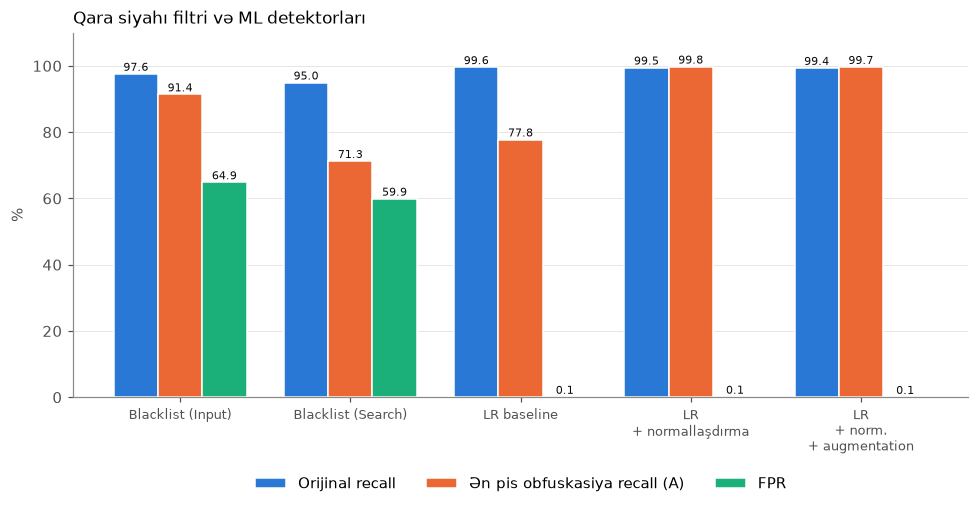

In [11]:
metrics_plot = {"Orijinal recall": "recall_original", "Ən pis obfuskasiya recall (A)": "worst_obfuscation_recall",
                "FPR": "fpr_original"}
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(main))
w = 0.26
for k, ((label, col), c) in enumerate(zip(metrics_plot.items(), colors)):
    vals = main[col].to_numpy() * 100
    bars = ax.bar(x + (k - 1) * w, vals, width=w, color=c, label=label, edgecolor="white", linewidth=1)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.1f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7, color="#0b0b0b")
ax.set_xticks(x, [n.replace(" + ", "\n+ ") for n in main.index], fontsize=8.5)
ax.set_ylabel("%")
ax.set_ylim(0, 110)
ax.set_title("Qara siyahı filtri və ML detektorları", loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
save_fig(fig, "05_blacklist_vs_ml.png")
plt.show()